# Tidy Data Project: 2008 Olympic Medalists

This is the Jupiter Notebook for my Tidy Data Project, using the data file regarding the 2008 Olympic medalists.

## Section One: Data Cleaning and Tidying Process

In general, when tidying data, one must ensure that every variable forms a column, every observation forms a row, and every value is a cell. In my case, that meant the columns should be defined as the sex, the sport, athlete name, and the medal type (gold, silver, bronze, or null). Currently, the columns combine the sport and sex of the athlete, making data manipulation challenging. 

In tidying the data, I must first define my dataframe. This brings in my external csv such that it can be interpreted as a pandas dataframe (pandas cheat sheet).

In [31]:
import pandas as pd # import pandas dictionary to be referred to later
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

df_olymp= pd.read_csv('olympics_08_medalists.csv') # define dataframe
df_olymp.head()

,medalist_name,male_archery,female_archery,male_athletics,female_athletics,male_badminton,female_badminton,male_baseball,male_basketball,female_basketball,...,female_beach volleyball,male_volleyball,female_volleyball,male_water polo,female_water polo,male_weightlifting,female_weightlifting,male_freestyle wrestling,female_freestyle wrestling,male_greco-roman wrestling
0,Aaron Armstrong,NaN,NaN,gold,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Aaron Peirsol,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Abdullo Tangriev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Abeer Abdelrahman,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,bronze,NaN,NaN,NaN
4,Abhinav,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Next, I need to melt my dataframe such that the different variables are defined. This step is what reorients the columns such that the different values of sex and sport are now correctly different rows. As demonstrated in the Pandas Cheat Sheet, it is important that values themselves, such as the specific sport and sex, not be names of columns. Values should instead be cells within the column of the variable, titled "sex" or "sport".

In [32]:
df_olymp_melted = pd.melt(df_olymp,
                          id_vars = 'medalist_name', # holds constant the column for medalist name
                          value_vars = df_olymp.columns[1:], # selects all the columns to be reoriented
                          var_name = 'sex_sport', # renames the column now containing the previous column names
                          value_name='Medal') #names the column containing all of the values from the original untidy dataframe

df_olymp_melted

,medalist_name,sex_sport,Medal
0,Aaron Armstrong,male_archery,NaN
1,Aaron Peirsol,male_archery,NaN
2,Abdullo Tangriev,male_archery,NaN
3,Abeer Abdelrahman,male_archery,NaN
4,Abhinav,male_archery,NaN
...,...,...,...
131245,Éver Banega,male_greco-roman wrestling,NaN
131246,Ólafur Stefánsson,male_greco-roman wrestling,NaN
131247,Óscar Brayson,male_greco-roman wrestling,NaN
131248,Łukasz Pawłowski,male_greco-roman wrestling,NaN


Now, I still need to split the dataframe such that the sex and sport are different columns, with correct formatting. This aligns with the tidy data principle discussed in the article Tidy Data, by Hadley Wickham. There should not be multiple variables/variable types in one column. In this case, the dataset included two different categorical values in one column (the sex and the sport).

In [33]:
df_olymp_melted[['Sex','Sport']] = df_olymp_melted['sex_sport'].str.split('_', expand=True) # splits the column with two variables into two columns, expand=true makes them two columns instead of a list of two variables
df_olymp_melted_tidy = df_olymp_melted.drop('sex_sport', axis=1) # gets rid of messy/unwanted column
df_olymp_melted_tidy

,medalist_name,Medal,Sex,Sport
0,Aaron Armstrong,NaN,male,archery
1,Aaron Peirsol,NaN,male,archery
2,Abdullo Tangriev,NaN,male,archery
3,Abeer Abdelrahman,NaN,male,archery
4,Abhinav,NaN,male,archery
...,...,...,...,...
131245,Éver Banega,NaN,male,greco-roman wrestling
131246,Ólafur Stefánsson,NaN,male,greco-roman wrestling
131247,Óscar Brayson,NaN,male,greco-roman wrestling
131248,Łukasz Pawłowski,NaN,male,greco-roman wrestling


The next step is to tidy the data with regards to the missing data, as not every individual competeted in every sport. Every medalist is now cited with a null value for all sports they did not compete in, and their own sport with the opposite sex. To clean this, we must drop all of the rows with null values. This has no impact on the aggregates, as they simply had nothing to do with those competitions. These missing values are not dependent on the value of the medal (i.e. the null values do NOT represent gold, silver, or bronze medals). In this instance, as emphasized in the article Tidy Data, we could either impute a value or delete the null observational cells. I chose to delete these rows because the individuals did not compete in those sports, there is not some medal with an unknown value. 

In [34]:
df_olymp_melted_tidy = df_olymp_melted_tidy.dropna().reset_index(drop=True) # .dropna() removes all of the null values from the data frame, reset the index for simplicity
df_olymp_melted_tidy

,medalist_name,Medal,Sex,Sport
0,Bair Badënov,bronze,male,archery
1,Ilario Di Buò,silver,male,archery
2,Im Dong-hyun,gold,male,archery
3,Jiang Lin,bronze,male,archery
4,Lee Chang-hwan,gold,male,archery
...,...,...,...,...
1870,Steeve Guénot,gold,male,greco-roman wrestling
1871,Yannick Szczepaniak,bronze,male,greco-roman wrestling
1872,Yavor Yanakiev,bronze,male,greco-roman wrestling
1873,Yury Patrikeyev,bronze,male,greco-roman wrestling


## Section Two: Analysis of the Data

### Part One: Pivot Tables and Aggregation Functions

Here, I am creating a pivot table which countes the total number of medals from each material for each sex within each sport. Although this is not an aggregate in the way one initially considers (mean, mode, median, etc.), it provides valuable numerical information about categorical data. I also found it helpful to sum the total number of medals for each given sport and create a new column with that value, such that I could then sort the sports from most to least total medals. 

In [35]:
df_pivot = df_olymp_melted_tidy.pivot_table( # create a pivot table with the Sport as the index
    index='Sport',
    columns = ['Medal','Sex'],
    values = 'medalist_name',
    aggfunc='count' # agg function is the total number of ___ medals in that sport for each sex 
)
df_pivot = df_pivot[['gold','silver','bronze']] # reorganize in 1 2 3 order 

df_pivot['Total'] = df_pivot.sum(axis=1) # adding a column to the pivot table with the total number of medals for a given sport

df_pivot = df_pivot.sort_values(by='Total', ascending = False) # ordering the sports from most medals to fewest medals

df_pivot

Medal                   gold       silver       bronze        Total
Sex                   female  male female  male female  male       
Sport                                                              
athletics               27.0  25.0   28.0  31.0   26.0  29.0  166.0
rowing                  20.0  28.0   20.0  28.0   18.0  27.0  141.0
swimming                21.0  18.0   20.0  23.0   22.0  21.0  125.0
association football    18.0  19.0   18.0  18.0   18.0  18.0  109.0
field hockey            16.0  17.0   16.0  16.0   16.0  17.0   98.0
handball                14.0  15.0   14.0  14.0   14.0  14.0   85.0
water polo              13.0  13.0   13.0  13.0   13.0  13.0   78.0
canoeing and kayaking    7.0  17.0    6.0  17.0    8.0  19.0   74.0
baseball                 NaN  24.0    NaN  24.0    NaN  24.0   72.0
volleyball              12.0  12.0   12.0  12.0   12.0  12.0   72.0
basketball              12.0  11.0   12.0  12.0   12.0  12.0   71.0
judo                     7.0   7.0    7.0   7.0   14.0  14.0   56.0
sailing                  7.0  11.0    7.0  11.0    7.0  11.0   54.0
fencing                 11.0   7.0   10.0  11.0    5.0  10.0   54.0
artistic gymnastics      7.0   7.0    6.0  10.0    7.0  12.0   49.0
softball                15.0   NaN   15.0   NaN   15.0   NaN   45.0
weightlifting            7.0   8.0    7.0   8.0    7.0   8.0   45.0
freestyle wrestling      4.0   7.0    4.0   7.0    8.0  14.0   44.0
track cycling            3.0   8.0    3.0  14.0    3.0  13.0   44.0
boxing                   NaN  11.0    NaN  11.0    NaN  22.0   44.0
shooting sport           6.0   8.0    5.0   9.0    6.0   9.0   43.0
equestrian sport         4.0   7.0    7.0   6.0    9.0   5.0   38.0
taekwondo                4.0   4.0    4.0   4.0    8.0   8.0   32.0
synchronized swimming    9.0   NaN    9.0   NaN   11.0   NaN   29.0
diving                   2.0   5.0    5.0   6.0    6.0   5.0   29.0
greco-roman wrestling    NaN   7.0    NaN   7.0    NaN  13.0   27.0
badminton                3.0   4.0    4.0   4.0    3.0   4.0   22.0
rhythmic gymnastics      7.0   NaN    7.0   NaN    7.0   NaN   21.0
archery                  2.0   3.0    3.0   4.0    4.0   4.0   20.0
table tennis             1.0   1.0    4.0   4.0    4.0   4.0   18.0
tennis                   3.0   3.0    3.0   3.0    3.0   3.0   18.0
beach volleyball         2.0   2.0    2.0   2.0    2.0   2.0   12.0
road bicycle racing      2.0   1.0    2.0   2.0    2.0   2.0   11.0
mountain biking          1.0   1.0    1.0   1.0    1.0   1.0    6.0
trampoline gymnastics    1.0   1.0    1.0   1.0    1.0   1.0    6.0
triathlon                1.0   1.0    1.0   1.0    1.0   1.0    6.0
bmx                      1.0   1.0    1.0   1.0    1.0   1.0    6.0
modern pentathlon        1.0   1.0    1.0   1.0    NaN   1.0    5.0

Next, I created a pivot table to aggregate and find the most common medal material for each sex within each sport. If there are materials with the same number of medals, the aggregate mode is indicated as a list. 

In [36]:
df_pivot1 = df_olymp_melted_tidy.pivot_table( # create a pivot table with the Sport as the index
    index='Sport',
    columns = 'Sex',
    values = 'Medal',
    aggfunc=lambda x: x.mode() # agg function is the most earned medal (i.e. mode) for each sport
)
# lists all three if equal counts
df_pivot1

Sex,female,male
Sport,,
archery,bronze,"[bronze, silver]"
artistic gymnastics,"[bronze, gold]",bronze
association football,"[bronze, gold, silver]",gold
athletics,silver,silver
badminton,silver,"[bronze, gold, silver]"
baseball,NaN,"[bronze, gold, silver]"
basketball,"[bronze, gold, silver]","[bronze, silver]"
beach volleyball,"[bronze, gold, silver]","[bronze, gold, silver]"
bmx,"[bronze, gold, silver]","[bronze, gold, silver]"


### Part Two: Visualizations

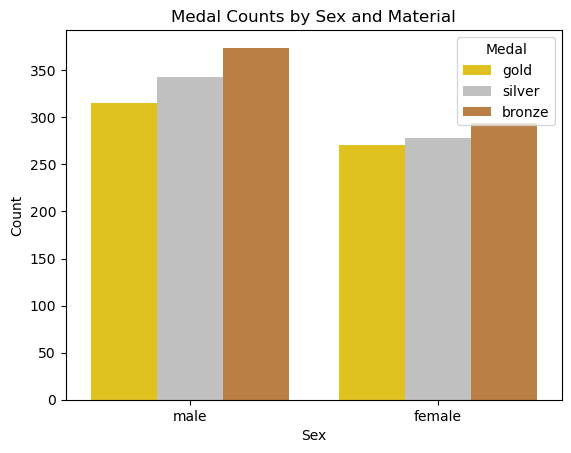

In [37]:
medal_colors = {'gold': '#FFD700','silver':'#C0C0C0', 'bronze':'#CD7F32'}

plt.figure()
sns.countplot(
    data = df_olymp_melted_tidy,
    x = 'Sex',
    hue = 'Medal',
    hue_order = ['gold', 'silver', 'bronze'],
    palette = medal_colors
)

plt.title('Medal Counts by Sex and Material')
plt.xlabel('Sex')
plt.ylabel('Count')
plt.legend(title = "Medal")

plt.show()

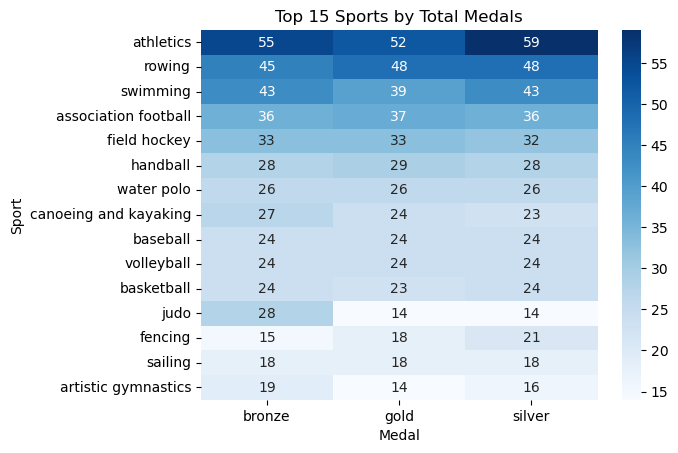

In [38]:
top_15_sports = (df_olymp_melted_tidy['Sport'] # using parenthesis to method chain and select for the indices of the 15 sports with the highest value count
                 .value_counts()
                 .head(15)
                 .index
                 )

df_top_15_sports = df_olymp_melted_tidy[ # creating a dataframe from the tidy dataframe with only the top 15 sports
    df_olymp_melted_tidy['Sport'].isin(top_15_sports)
    ] 

df_pivot2 = pd.crosstab( # creating a more useful pivot table for specific visualization need, counts of medals vs sport
    df_top_15_sports['Sport'], 
    df_top_15_sports['Medal']
    ) 

df_pivot2['Total'] = df_pivot2.sum(axis = 1) # need to create column of totals to order sports from most to least
df_pivot2 = (
    df_pivot2.sort_values(by = 'Total', ascending = False)
    .drop(columns='Total') # need to then drop totals for heatmap visualization
)

plt.figure()
sns.heatmap(df_pivot2,annot=True,cmap = 'Blues') # annot=True writes number of medals on top of grid
plt.title('Top 15 Sports by Total Medals')
plt.show()

I was curious to see if there was any relationship between the total number of medals for a sport, and the ratio between female and male medals. So, I created a scatter plot comparing these two numerical values. As you can see below, there is no correlation. 

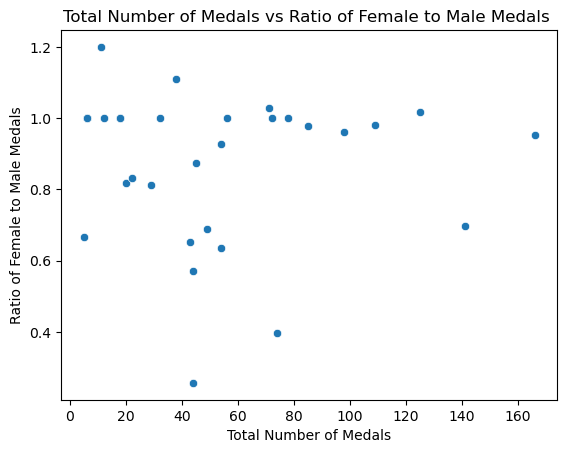

In [ ]:
df_pivot3 = (
    df_olymp_melted_tidy.groupby(['Sport','Sex'])
    .size() # fills the values with the counts for each combination of sport and sex
    .unstack() # unstacks the pivot table to a reshaped dataframe 
     .dropna()  # drops rows without any male medals, which would return infinity  
)

# creating new columns with calculated values
df_pivot3['Ratio'] = df_pivot3['female'] / df_pivot3['male']
df_pivot3['Total'] = df_pivot3['female'] +  df_pivot3['male']

plt.figure()
sns.scatterplot(x=df_pivot3['Total'], y = df_pivot3['Ratio'])
plt.title('Total Number of Medals vs Ratio of Female to Male Medals ')
plt.xlabel('Total Number of Medals')
plt.ylabel('Ratio of Female to Male Medals')
plt.show()

Sources Used:
- https://stackoverflow.com/questions/15891038/change-column-type-in-pandas 
- https://stackoverflow.com/questions/51004029/create-a-new-dataframe-based-on-rows-with-a-certain-value 
- https://stackoverflow.com/questions/20461165/how-to-convert-index-of-a-pandas-dataframe-into-a-column
- https://stackoverflow.com/questions/20490274/how-to-reset-index-in-a-pandas-dataframe
- https://matplotlib.org/stable/gallery/subplots_axes_and_figures/subplots_demo.html
- https://github.com/julia-dunn/DUNN-Python-Portfolio/tree/main/TidyData-Project
- https://pandas.pydata.org/docs/reference/api/pandas.crosstab.html 
- https://python-graph-gallery.com/scatter-plot/